# Validación externa en `gaitpdb`

## Entrega P2

En `gaitndd` los controles son 27 años más jóvenes que los pacientes con Parkinson. Por eso, un modelo que separa Parkinson de control en esa cohorte puede estar aprendiendo edad. En P1 se propuso usar `gaitpdb` para resolverlo: ahí la diferencia de edad entre grupos es de 2.6 años.

El experimento es el siguiente. Se entrena con los 31 sujetos de Parkinson y control de `gaitndd` y se evalúa, sin reentrenar, en los 165 sujetos de `gaitpdb`. Si el modelo de marcha conserva su capacidad y el modelo que solo usa la edad la pierde, la señal de marcha no era edad disfrazada.

Hay un obstáculo previo: `gaitpdb` no trae series de zancada ya calculadas, sino la fuerza plantar cruda. Hay que extraer las zancadas con un método propio.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/jeraldinedione/proyecto-machine-learning.git"


def raiz_del_proyecto(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "src" / "gait").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto")


if "google.colab" in sys.modules:
    if not Path("marcha").exists():
        subprocess.run(["git", "clone", "--quiet", REPOSITORIO, "marcha"], check=True)
    RAIZ = Path("marcha").resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(RAIZ / "requirements.txt")],
        check=True,
    )
else:
    RAIZ = raiz_del_proyecto(Path.cwd())

sys.path.insert(0, str(RAIZ / "src"))
print(RAIZ)

/Users/nllerenas/Chiwawa/proyecto-machine-learning


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score, roc_curve

from gait import cohort, config, download, evaluation, features, gaitndd, gaitpdb, models, plots, quality

download.fetch(config.GAITNDD)
download.fetch(config.GAITPDB)
plots.use_paper_style()
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---

## 1. De la fuerza plantar a las zancadas

Cada registro tiene la fuerza vertical total bajo cada pie, en newtons, a 100 Hz. Durante el balanceo la fuerza es prácticamente cero, así que el contacto se detecta con un umbral:

1. **Umbral de contacto**: 5 % del percentil 99 de la fuerza de ese pie en ese registro. Es relativo para no depender del peso del sujeto ni de la calibración del sensor.
2. **Limpieza**: los huecos de menos de 0.1 s dentro de un contacto se rellenan y los contactos de menos de 0.1 s se eliminan. Ninguna fase real de la marcha dura tan poco.
3. **Eventos**: el inicio de cada contacto es un apoyo de talón y el final, un despegue.
4. **Zancada**: de un apoyo de talón izquierdo al siguiente. Dentro de ella se buscan el despegue izquierdo, el apoyo y el despegue derecho; el apoyo doble es el tiempo con ambos pies en contacto.

El resultado tiene las mismas columnas que los archivos `.ts` de `gaitndd`, de modo que se le aplican las mismas reglas de calidad y el mismo cálculo de descriptores. Solo se usa la primera caminata de cada sujeto (`_01`), la de referencia; varias de las siguientes corresponden a condiciones experimentales, como la doble tarea, que alteran el ritmo a propósito.

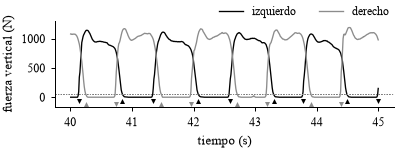

In [3]:
fuerzas = gaitpdb.read_forces("GaCo01_01")
tramo = (fuerzas.time_s >= 40) & (fuerzas.time_s < 45)

fig, ax = plt.subplots(figsize=(plots.COLUMN_WIDTH, 1.45))
for columna, color, nombre, altura in [("left_total", "black", "izquierdo", -60), ("right_total", "0.55", "derecho", -120)]:
    senal = fuerzas[columna].to_numpy()
    contacto = gaitpdb.contact_mask(senal)
    inicios, finales = gaitpdb.gait_events(contacto)
    ax.plot(fuerzas.time_s[tramo], senal[tramo], color=color, lw=0.8, label=nombre)
    tiempo = fuerzas.time_s.to_numpy()
    for evento, marcador in [(inicios, "v"), (finales, "^")]:
        visibles = evento[tramo.to_numpy()[evento]]
        ax.scatter(tiempo[visibles], np.full(len(visibles), altura), marker=marcador, s=9, color=color, lw=0)
    ax.axhline(gaitpdb.CONTACT_FRACTION * np.percentile(senal, 99), color=color, ls=":", lw=0.6)
ax.set_xlabel("tiempo (s)")
ax.set_ylabel("fuerza vertical (N)")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.98), ncols=2, borderaxespad=0)
ax.set_ylim(-170, 1300)
fig.tight_layout()
plots.save(fig, "deteccion_eventos")

Triángulos hacia abajo: apoyos de talón; hacia arriba: despegues. La línea punteada es el umbral de cada pie. Los eventos caen donde se esperan visualmente; la validación cuantitativa está en `tests/test_modeling.py`, donde una señal sintética con zancada de 1.1 s y apoyo del 62 % se recupera con error menor a 0.01 s.

In [4]:
%%time
crudas_externas = gaitpdb.read_baseline_strides()
revisadas = quality.stride_violations(crudas_externas)
externas = quality.drop_violations(revisadas)

calidad = revisadas.groupby(["study", "group"]).agg(
    sujetos=("record", "nunique"),
    zancadas=("stride_index", "size"),
    pct_descartado=("any_violation", "mean"),
)
calidad["pct_descartado"] *= 100
calidad["zancadas por sujeto"] = calidad.zancadas / calidad.sujetos
calidad["zancada mediana (s)"] = externas.groupby(["study", "group"]).stride_left_s.median()
calidad["apoyo doble mediano (%)"] = externas.groupby(["study", "group"]).double_support_pct.median()
calidad

CPU times: user 1.28 s, sys: 42.6 ms, total: 1.32 s
Wall time: 1.38 s


sujetos  zancadas  pct_descartado  zancadas por sujeto  zancada mediana (s)  apoyo doble mediano (%)
study group                                                                                                        
Ga    control       18      1928           0.363              107.111                1.080                   22.727
      park          29      3044           0.624              104.966                1.090                   27.885
Ju    control       25      1845           0.108               73.800                1.080                   24.074
      park          29      2545           0.629               87.759                1.060                   26.923
Si    control       29      3190           0.031              110.000                1.070                   25.000
      park          35      3630           0.358              103.714                1.120                   26.126

Menos del 1 % de las zancadas viola alguna regla, frente al 5.9 % de ELA en `gaitndd`. Las duraciones (≈ 1.1 s) y el apoyo doble (25 % a 28 %) están en el rango de la cohorte principal.

---

## 2. Armonizar las dos cohortes

Las caminatas de `gaitpdb` duran unos dos minutos; las de `gaitndd`, cinco. DFA, la entropía muestral y en menor medida el CV dependen del largo de la serie: con más zancadas aparecen más fluctuaciones lentas. Para que el modelo vea en entrenamiento series del mismo largo que en la prueba, en `gaitndd` se usan solo los primeros 110 s de zancadas válidas.

Además se distinguen dos conjuntos de descriptores:

- **Tiempos de zancada** (8 variables): solo dependen de los instantes de apoyo de talón, que ambos sistemas detectan bien.
- **Todos** (12 variables): agrega las fases (balanceo y apoyo doble), que dependen del umbral con que se detecta el despegue. `gaitndd` usó un sensor y un algoritmo distintos, así que estas variables pueden no ser comparables.

El conjunto principal se fija antes de mirar resultados: tiempos de zancada.

In [5]:
DURACION_S = 110

sujetos = gaitndd.read_subject_table()
zancadas = cohort.clean_strides(gaitndd.read_all_strides())
pd_control = zancadas[zancadas.group.isin(["control", "park"])]
entrenamiento = cohort.subject_dataset(cohort.first_strides(pd_control, DURACION_S), sujetos)

demografia = gaitpdb.read_subject_table().rename(columns={"record_id": "record"})
prueba = features.build_feature_table(externas, features.extended_features)
prueba = prueba.merge(demografia[["record", "study", "age", "sex"]], on="record", how="left")
prueba["male"] = prueba.sex.eq("m").astype(int)

print(f"entrenamiento (gaitndd): {len(entrenamiento)} sujetos, mediana de {entrenamiento.n_strides.median():.0f} zancadas")
print(f"prueba (gaitpdb): {len(prueba)} sujetos, mediana de {prueba.n_strides.median():.0f} zancadas")
print()
edades = pd.DataFrame({
    "gaitndd": entrenamiento.groupby("group").age.mean(),
    "gaitpdb": prueba.groupby("group").age.mean(),
}).rename(index=config.GROUP_LABELS)
edades.loc["diferencia"] = edades.loc["Parkinson"] - edades.loc["Control"]
edades.round(1)

entrenamiento (gaitndd): 31 sujetos, mediana de 100 zancadas
prueba (gaitpdb): 165 sujetos, mediana de 103 zancadas



,gaitndd,gaitpdb
group,,
Control,39.300,63.700
Parkinson,66.800,66.300
diferencia,27.500,2.600


In [6]:
comparacion = pd.concat({
    "gaitndd": entrenamiento.groupby("group")[config.TIMING_FEATURES].median(),
    "gaitpdb": prueba.groupby("group")[config.TIMING_FEATURES].median(),
}).T
comparacion.index = [config.FEATURE_LABELS[f] for f in comparacion.index]
comparacion.columns = [f"{cohorte} {config.GROUP_SHORT[g]}" for cohorte, g in comparacion.columns]
comparacion.to_csv(config.TABLES_DIR / "cohortes_comparadas.csv")
comparacion

,gaitndd Ctrl,gaitndd EP,gaitpdb Ctrl,gaitpdb EP
duración media,1.075,1.133,1.085,1.110
CV de zancada,0.040,0.058,0.049,0.060
IQR de zancada,0.032,0.056,0.030,0.040
variab. sucesiva,0.037,0.069,0.053,0.072
asimetría de zancada,0.013,0.054,0.065,0.122
autocorrelación,0.544,0.401,0.308,0.197
DFA α,0.922,0.911,0.777,0.709
entropía muestral,1.489,1.602,1.225,1.016


In [7]:
por_estudio = prueba.groupby(["study", "group"])[["stride_cv", "dfa_alpha", "sample_entropy"]].median().unstack()
por_estudio.round(3)

stride_cv       dfa_alpha       sample_entropy      
group   control  park   control  park        control  park
study                                                     
Ga        0.077 0.063     0.759 0.610          0.788 1.063
Ju        0.059 0.074     0.742 0.718          1.034 0.939
Si        0.038 0.053     0.800 0.716          1.714 1.039

Hay desplazamiento de dominio. Dentro de cada cohorte los pacientes tienen más variabilidad y menor α que los controles, pero el nivel cambia entre cohortes y entre estudios de `gaitpdb`. Un umbral aprendido en `gaitndd` puede quedar corrido en `gaitpdb` aunque el orden entre sujetos se conserve. Por eso la métrica principal es el AUC, que solo evalúa el orden; la exactitud balanceada con el umbral 0.5 se reporta como complemento.

---

## 3. Transporte de `gaitndd` a `gaitpdb`

Para cada conjunto de variables y cada modelo:

1. **Interna**: validación cruzada anidada 5 × 10 dentro de los 31 sujetos de `gaitndd`. Es lo que se reportaría si no hubiera cohorte externa.
2. **Externa**: se ajustan los hiperparámetros con validación interna sobre los 31 sujetos, se entrena con todos ellos y se predice `gaitpdb`. El intervalo del AUC es bootstrap estratificado (2000 remuestreos de sujetos).

In [8]:
%%time
conjuntos = {
    "tiempos de zancada": config.TIMING_FEATURES,
    "todos los descriptores": config.GAIT_FEATURES,
    "edad": ["age"],
    "edad y sexo": config.DEMOGRAPHIC_FEATURES,
}
particiones_internas = evaluation.record_splits(entrenamiento, n_repeats=10)
es_parkinson = prueba.group.eq("park").to_numpy()

filas, puntajes_externos, modelos_externos = [], {}, {}
for conjunto, variables in conjuntos.items():
    for spec in [models.logistic(variables), models.random_forest(variables)]:
        interna = evaluation.repeat_metrics(evaluation.nested_cv(spec, entrenamiento, particiones_internas))
        modelo, _ = evaluation.fit_model(spec, entrenamiento)
        puntaje = modelo.predict_proba(prueba[variables])[:, list(modelo.classes_).index("park")]
        puntajes_externos[(conjunto, spec.label)] = puntaje
        modelos_externos[(conjunto, spec.label)] = modelo
        auc, bajo, alto = evaluation.bootstrap_auc(es_parkinson, puntaje)
        prediccion = puntaje >= 0.5
        filas.append({
            "variables": conjunto,
            "modelo": spec.label,
            "AUC interna": interna.auc.mean(),
            "AUC externa": auc,
            "IC 95 %": f"[{bajo:.2f}, {alto:.2f}]",
            "exactitud bal. externa": balanced_accuracy_score(es_parkinson, prediccion),
            "sensibilidad": recall_score(es_parkinson, prediccion),
            "especificidad": recall_score(~es_parkinson, ~prediccion),
        })
transporte = pd.DataFrame(filas).set_index(["variables", "modelo"])
transporte.to_csv(config.TABLES_DIR / "validacion_externa.csv")
transporte

CPU times: user 54.8 s, sys: 1.71 s, total: 56.6 s
Wall time: 3min 33s


AUC interna  AUC externa       IC 95 %  exactitud bal. externa  sensibilidad  especificidad
variables              modelo                                                                                                          
tiempos de zancada     Regresión logística        0.808        0.684  [0.60, 0.76]                   0.612         0.613          0.611
                       Bosque aleatorio           0.942        0.707  [0.63, 0.79]                   0.657         0.634          0.681
todos los descriptores Regresión logística        0.896        0.728  [0.65, 0.80]                   0.647         0.849          0.444
                       Bosque aleatorio           0.943        0.773  [0.70, 0.84]                   0.664         0.828          0.500
edad                   Regresión logística        0.845        0.593  [0.51, 0.68]                   0.607         0.505          0.708
                       Bosque aleatorio           0.740        0.522  [0.43, 0.61]                   0.497         0.925          0.069
edad y sexo            Regresión logística        0.859        0.585  [0.50, 0.67]                   0.542         0.806          0.278
                       Bosque aleatorio           0.821        0.568  [0.48, 0.65]                   0.490         0.925          0.056

La pregunta central de este cuaderno tiene una respuesta clara. Los modelos que solo usan la edad separan Parkinson de control en `gaitndd` con AUC interna de 0.74–0.85, pero en `gaitpdb` caen a 0.52–0.59 (el intervalo del bosque incluye 0.5). Los modelos de marcha también pierden (con tiempos de zancada, de 0.81–0.94 a 0.68–0.71), pero su intervalo queda lejos de 0.5. La señal de la marcha no era edad disfrazada. La de la edad, en cambio, sí era una propiedad de cómo se armó `gaitndd`.

Con todos los descriptores el AUC externo es mayor (0.73–0.77), a pesar del riesgo de las fases. La exactitud balanceada no mejora en la misma medida porque el umbral queda corrido: la sensibilidad sube a 0.83–0.85 y la especificidad baja a 0.44–0.50. Es lo que se espera si el apoyo doble se mide de forma distinta en los dos sistemas y desplaza a todos los sujetos.

In [9]:
estudios = {}
for clave, puntaje in puntajes_externos.items():
    estudios[clave] = {
        estudio: roc_auc_score(es_parkinson[prueba.study == estudio], puntaje[prueba.study == estudio])
        for estudio in ["Ga", "Ju", "Si"]
    }
por_estudio_auc = pd.DataFrame(estudios).T
por_estudio_auc.columns = ["Ga", "Ju", "Si"]
por_estudio_auc.to_csv(config.TABLES_DIR / "validacion_externa_por_estudio.csv")
por_estudio_auc

Ga    Ju    Si
tiempos de zancada     Regresión logística 0.596 0.686 0.750
                       Bosque aleatorio    0.609 0.686 0.788
todos los descriptores Regresión logística 0.634 0.693 0.870
                       Bosque aleatorio    0.732 0.758 0.849
edad                   Regresión logística 0.528 0.605 0.632
                       Bosque aleatorio    0.476 0.476 0.580
edad y sexo            Regresión logística 0.563 0.584 0.581
                       Bosque aleatorio    0.546 0.537 0.596

El transporte funciona mejor en los sujetos del estudio Si (AUC 0.75–0.87) y peor en los de Ga (0.60–0.73). Con 47 a 64 sujetos por estudio estas diferencias tienen intervalos amplios, y la base no documenta qué distingue a las caminatas de referencia de cada estudio, así que no se intenta explicarlas.

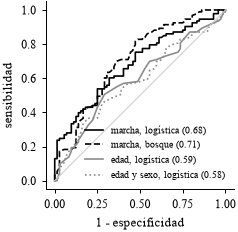

In [10]:
curvas = [
    (("tiempos de zancada", "Regresión logística"), "marcha, logística", "black", "-"),
    (("tiempos de zancada", "Bosque aleatorio"), "marcha, bosque", "black", "--"),
    (("edad", "Regresión logística"), "edad, logística", "0.55", "-"),
    (("edad y sexo", "Regresión logística"), "edad y sexo, logística", "0.55", ":"),
]
fig, ax = plt.subplots(figsize=(plots.COLUMN_WIDTH * 0.62, plots.COLUMN_WIDTH * 0.62))
for clave, nombre, color, estilo in curvas:
    fpr, tpr, _ = roc_curve(es_parkinson, puntajes_externos[clave])
    ax.plot(fpr, tpr, color=color, ls=estilo, lw=1.0, label=f"{nombre} ({transporte.loc[clave, 'AUC externa']:.2f})")
ax.plot([0, 1], [0, 1], color="0.8", lw=0.6)
ax.set_xlabel("1 - especificidad")
ax.set_ylabel("sensibilidad")
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=6, handlelength=1.8)
fig.tight_layout()
plots.save(fig, "roc_externa")

---

## 4. Referencia: entrenar y evaluar dentro de `gaitpdb`

Como techo de comparación se hace validación cruzada anidada dentro de `gaitpdb`, con el mismo esquema 5 × 10. Este número no mide transporte; dice cuánta señal tienen los descriptores en esta cohorte cuando el modelo puede aprender su nivel propio.

In [11]:
%%time
particiones_externas = evaluation.record_splits(prueba, n_repeats=10)
filas = []
for conjunto in ["tiempos de zancada", "todos los descriptores", "edad"]:
    for spec in [models.logistic(conjuntos[conjunto]), models.random_forest(conjuntos[conjunto])]:
        metricas = evaluation.repeat_metrics(evaluation.nested_cv(spec, prueba, particiones_externas))
        filas.append({
            "variables": conjunto,
            "modelo": spec.label,
            "exactitud bal.": f"{metricas.balanced_accuracy.mean():.3f} ± {metricas.balanced_accuracy.std(ddof=1):.3f}",
            "AUC": f"{metricas.auc.mean():.3f} ± {metricas.auc.std(ddof=1):.3f}",
        })
dentro = pd.DataFrame(filas).set_index(["variables", "modelo"])
dentro.to_csv(config.TABLES_DIR / "validacion_dentro_gaitpdb.csv")
dentro

CPU times: user 38.9 s, sys: 1.21 s, total: 40.1 s
Wall time: 2min 44s


exactitud bal.            AUC
variables              modelo                                           
tiempos de zancada     Regresión logística  0.659 ± 0.027  0.686 ± 0.023
                       Bosque aleatorio     0.666 ± 0.019  0.705 ± 0.014
todos los descriptores Regresión logística  0.723 ± 0.026  0.809 ± 0.017
                       Bosque aleatorio     0.706 ± 0.016  0.799 ± 0.016
edad                   Regresión logística  0.560 ± 0.019  0.577 ± 0.023
                       Bosque aleatorio     0.573 ± 0.032  0.513 ± 0.026

Entrenando y evaluando dentro de `gaitpdb`, los tiempos de zancada alcanzan un AUC de 0.69–0.71, prácticamente el mismo que se obtiene al transportar desde `gaitndd` (0.68–0.71). Un modelo entrenado en otra cohorte, con 31 sujetos y otro sensor, ordena a los sujetos de `gaitpdb` tan bien como uno entrenado con unos 130 sujetos de la misma cohorte. La edad, en cambio, apenas sirve dentro de `gaitpdb` (AUC 0.51–0.58).

---

## 5. Sensibilidad al umbral de contacto

El umbral del 5 % es una elección. Si los resultados dependieran mucho de él, la validación externa mediría la segmentación y no la marcha. Se repite la extracción con umbrales relativos de 2 %, 10 % y 20 % del percentil 99, y con un umbral fijo de 50 N, y se aplican **los mismos modelos ya entrenados** en `gaitndd` (el entrenamiento no depende de este umbral).

In [12]:
%%time
umbrales = {
    "2 %": {"fraction": 0.02},
    "5 % (usado)": {"fraction": 0.05},
    "10 %": {"fraction": 0.10},
    "20 %": {"fraction": 0.20},
    "50 N fijo": {"threshold_n": 50.0},
}
filas = []
for nombre, deteccion in umbrales.items():
    revisadas_u = quality.stride_violations(gaitpdb.read_baseline_strides(**deteccion))
    limpias_u = quality.drop_violations(revisadas_u)
    tabla_u = features.build_feature_table(limpias_u, features.extended_features)
    tabla_u = tabla_u.set_index("record").reindex(prueba.record).reset_index()
    fila = {
        "umbral": nombre,
        "zancadas por sujeto": limpias_u.groupby("record").size().median(),
        "% descartado": 100 * revisadas_u.any_violation.mean(),
        "apoyo doble mediano (%)": limpias_u.double_support_pct.median(),
    }
    for clave in [("tiempos de zancada", "Regresión logística"), ("tiempos de zancada", "Bosque aleatorio"), ("todos los descriptores", "Bosque aleatorio")]:
        modelo = modelos_externos[clave]
        variables = conjuntos[clave[0]]
        puntaje = modelo.predict_proba(tabla_u[variables])[:, list(modelo.classes_).index("park")]
        fila[f"AUC {clave[1].split()[0].lower()}, {clave[0]}"] = roc_auc_score(es_parkinson, puntaje)
    filas.append(fila)
sensibilidad_umbral = pd.DataFrame(filas).set_index("umbral")
sensibilidad_umbral.to_csv(config.TABLES_DIR / "sensibilidad_umbral.csv")
sensibilidad_umbral

CPU times: user 7.03 s, sys: 173 ms, total: 7.2 s
Wall time: 7.26 s


,zancadas por sujeto,% descartado,apoyo doble mediano (%),"AUC regresión, tiempos de zancada","AUC bosque, tiempos de zancada","AUC bosque, todos los descriptores"
umbral,,,,,,
2 %,102.000,0.661,29.808,0.643,0.733,0.783
5 % (usado),103.000,0.358,25.664,0.684,0.707,0.773
10 %,104.000,0.240,21.667,0.703,0.693,0.742
20 %,104.000,0.148,16.667,0.664,0.684,0.716
50 N fijo,103.000,0.352,25.664,0.690,0.724,0.783


Con umbrales entre 2 % y 20 %, o con 50 N fijos, el AUC de los modelos de tiempos de zancada se mueve entre 0.64 y 0.73. El apoyo doble mediano, en cambio, pasa de 30 % a 17 %, y el modelo con todos los descriptores pierde más a medida que sube el umbral (de 0.78 a 0.72). Es la justificación empírica de haber elegido los tiempos de zancada como conjunto principal: dependen de cuándo empieza cada contacto, no de cuándo se considera terminado.

---

## 6. Los 19 descriptores de P1 en la cohorte externa

La versión preliminar de la validación externa entrenó con los 19 descriptores de P1 sobre los registros completos de `gaitndd`. La regresión logística clasificó a todos los sujetos de `gaitpdb` como controles y el SVM a todos como Parkinson. Esta sección reproduce ese experimento con la extracción de este cuaderno para ver qué variables lo explican.

El número de zancadas y la duración observada no describen la marcha sino el protocolo: en `gaitndd` se registran cinco minutos y en `gaitpdb` dos.

In [13]:
completo = cohort.subject_dataset(pd_control, sujetos)
duracion = pd.DataFrame({
    "gaitndd, 5 min": completo[config.DURATION_FEATURES].median(),
    "gaitndd, 110 s": entrenamiento[config.DURATION_FEATURES].median(),
    "gaitpdb": prueba[config.DURATION_FEATURES].median(),
})
duracion

,"gaitndd, 5 min","gaitndd, 110 s",gaitpdb
n_strides,250.000,100.000,103.000
observed_span_s,276.853,109.280,117.580
cadence_strides_per_min,54.347,54.937,54.772


In [14]:
%%time
p1_sin_duracion = [f for f in config.P1_FEATURES if f not in config.DURATION_FEATURES]
variantes = {
    "19 de P1, registro completo": (completo, config.P1_FEATURES),
    "19 de P1, primeros 110 s": (entrenamiento, config.P1_FEATURES),
    "16 sin duración, registro completo": (completo, p1_sin_duracion),
    "8 tiempos de zancada, primeros 110 s": (entrenamiento, config.TIMING_FEATURES),
}
filas = []
for nombre, (tabla, variables) in variantes.items():
    for spec in [models.logistic(variables), models.svm(variables), models.random_forest(variables)]:
        modelo, _ = evaluation.fit_model(spec, tabla)
        puntaje = modelo.predict_proba(prueba[variables])[:, list(modelo.classes_).index("park")]
        prediccion = puntaje >= 0.5
        filas.append({
            "variables": nombre,
            "modelo": spec.label,
            "AUC": roc_auc_score(es_parkinson, puntaje),
            "exactitud bal.": balanced_accuracy_score(es_parkinson, prediccion),
            "% predicho EP": 100 * prediccion.mean(),
        })
variables_p1 = pd.DataFrame(filas).set_index(["variables", "modelo"])
variables_p1.to_csv(config.TABLES_DIR / "validacion_externa_p1.csv")
variables_p1

CPU times: user 1.07 s, sys: 43.5 ms, total: 1.11 s
Wall time: 3.89 s


AUC  exactitud bal.  % predicho EP
variables                            modelo                                                  
19 de P1, registro completo          Regresión logística 0.755           0.516          1.818
                                     SVM (RBF)           0.505           0.500        100.000
                                     Bosque aleatorio    0.762           0.671         67.879
19 de P1, primeros 110 s             Regresión logística 0.702           0.630         52.121
                                     SVM (RBF)           0.685           0.564         93.333
                                     Bosque aleatorio    0.756           0.683         67.879
16 sin duración, registro completo   Regresión logística 0.746           0.703         47.879
                                     SVM (RBF)           0.756           0.687         60.000
                                     Bosque aleatorio    0.772           0.671         67.879
8 tiempos de zancada, primeros 110 s Regresión logística 0.684           0.612         51.515
                                     SVM (RBF)           0.670           0.603         72.727
                                     Bosque aleatorio    0.707           0.657         49.697

El experimento preliminar se reproduce: con los 19 descriptores y los registros completos, la regresión logística predice Parkinson para solo el 1.8 % de los sujetos y el SVM para el 100 %, ambos con exactitud balanceada de 0.50. Sin embargo, el AUC de la logística es 0.755. El modelo ordena bien a los sujetos; lo que falla es el umbral.

La causa está en la tabla anterior. El número de zancadas es 250 en `gaitndd` y 103 en `gaitpdb`, y la duración observada, 277 s frente a 118 s; la diferencia viene del protocolo, no de la marcha. Basta con recortar `gaitndd` a 110 s o quitar esas tres variables para que la exactitud balanceada vuelva a 0.63–0.70.

El bosque no colapsa porque todos los sujetos de `gaitpdb` caen del mismo lado de cada división sobre esas variables y el modelo termina decidiendo con las demás. Es una propiedad accidental del modelo, no algo en lo que convenga confiar.